In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [25]:
df = pd.read_csv("/home/patel-krish/anaconda3/BrainyBeam/heart.csv")
df = df.drop_duplicates().reset_index(drop=True)

X = df.drop(columns=["target"]).to_numpy(dtype=float)
y = df["target"].to_numpy()

if np.isnan(X).any():
    raise ValueError("Please handle missing feature values first.")

y = np.where(y == 1, 1.0, -1.0)

In [26]:
rng = np.random.default_rng(42)

train_idx = []
test_idx = []

for label in [-1.0, 1.0]:
    idx = np.where(y == label)[0]
    rng.shuffle(idx)

    n_test = max(1, int(round(0.2 * len(idx))))

    test_idx.extend(idx[:n_test])
    train_idx.extend(idx[n_test:])

train_idx = np.array(train_idx)
test_idx = np.array(test_idx)

rng.shuffle(train_idx)
rng.shuffle(test_idx)

X_train = X[train_idx]
X_test = X[test_idx]
y_train = y[train_idx]
y_test = y[test_idx]

In [27]:
mean = X_train.mean(axis=0)
std = X_train.std(axis=0)
std[std == 0] = 1

X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

In [28]:
def polynomial_kernel(A, B, degree=3, coef0=1.0):
    return (A @ B.T + coef0) ** degree


def rbf_kernel(A, B, gamma=None):
    if gamma is None:
        gamma = 1.0 / A.shape[1]

    A_sq = np.sum(A ** 2, axis=1).reshape(-1, 1)
    B_sq = np.sum(B ** 2, axis=1).reshape(1, -1)

    distances = A_sq + B_sq - 2 * (A @ B.T)
    distances = np.maximum(distances, 0)

    return np.exp(-gamma * distances)

In [29]:
class KernelSVM:

    def __init__(
        self,
        kernel="rbf",
        C=1.0,
        learning_rate=0.01,
        epochs=1500,
        degree=3,
        gamma=None,
        coef0=1.0
    ):
        self.kernel = kernel
        self.C = C
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.degree = degree
        self.gamma = gamma
        self.coef0 = coef0

        self.alpha = None
        self.X_train = None
        self.y_train = None
        self.bias = 0.0
        self.loss_history = []

    def make_kernel(self, A, B):
        if self.kernel == "polynomial":
            return polynomial_kernel(
                A, B,
                degree=self.degree,
                coef0=self.coef0
            )

        if self.kernel == "rbf":
            return rbf_kernel(A, B, gamma=self.gamma)

        raise ValueError("Unknown kernel type.")

    def fit(self, X, y):
        self.X_train = X.copy()
        self.y_train = y.copy()

        n = len(y)

        K = self.make_kernel(X, X)

       
        Q = np.outer(y, y) * K

        self.alpha = np.zeros(n)
        self.bias = 0.0
        self.loss_history = []

        largest_eigenvalue = np.linalg.norm(Q, ord=2)
        step = 1.0 / max(largest_eigenvalue, 1.0)

        for epoch in range(self.epochs):

            gradient = 1.0 - Q @ self.alpha

            self.alpha = np.clip(
                self.alpha + step * gradient,
                0.0,
                self.C
            )

            if epoch % 10 == 0 or epoch == self.epochs - 1:
                objective = (
                    np.sum(self.alpha)
                    - 0.5 * self.alpha @ Q @ self.alpha
                )
                self.loss_history.append(objective)

        self.support_mask = self.alpha > 1e-5

        margin_mask = (
            (self.alpha > 1e-5)
            & (self.alpha < self.C - 1e-5)
        )

        decision_train = (
            K @ (self.alpha * y)
        )

        if np.any(margin_mask):
            self.bias = np.mean(
                y[margin_mask] - decision_train[margin_mask]
            )
        else:
            self.bias = np.median(
                y[self.support_mask]
                - decision_train[self.support_mask]
            ) if np.any(self.support_mask) else 0.0

        return self

    def decision_function(self, X):
        K_test = self.make_kernel(X, self.X_train)

        return (
            K_test @ (self.alpha * self.y_train)
            + self.bias
        )

    def predict(self, X):
        return np.where(
            self.decision_function(X) >= 0,
            1.0,
            -1.0
        )

    def support_vector_count(self):
        return int(np.sum(self.support_mask))

In [30]:
def calculate_metrics(y_true, y_pred):
    TP = np.sum((y_true == 1) & (y_pred == 1))
    TN = np.sum((y_true == -1) & (y_pred == -1))
    FP = np.sum((y_true == -1) & (y_pred == 1))
    FN = np.sum((y_true == 1) & (y_pred == -1))

    accuracy = (TP + TN) / len(y_true)

    precision = TP / (TP + FP) if TP + FP else 0.0
    recall = TP / (TP + FN) if TP + FN else 0.0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )

    return accuracy, precision, recall, f1

In [31]:
models = {
    "Polynomial": KernelSVM(
        kernel="polynomial",
        C=1.0,
        degree=2,
        coef0=1.0,
        epochs=1500
    ),

    "RBF": KernelSVM(
        kernel="rbf",
        C=1.0,
        gamma=1.0 / X_train.shape[1],
        epochs=1500
    )
}

results = []

for name, model in models.items():
    print(f"\nTraining {name} kernel SVM...")

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    accuracy, precision, recall, f1 = calculate_metrics(
        y_test, predictions
    )

    results.append({
        "Kernel": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "Support Vectors": model.support_vector_count(),
        "Support Vector %": (
            100 * model.support_vector_count() / len(X_train)
        )
    })

    print("Accuracy:", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1 score:", round(f1, 4))
    print("Support vectors:", model.support_vector_count())


Training Polynomial kernel SVM...
Accuracy: 0.7213
Precision: 0.7353
Recall: 0.7576
F1 score: 0.7463
Support vectors: 112

Training RBF kernel SVM...
Accuracy: 0.8852
Precision: 0.8421
Recall: 0.9697
F1 score: 0.9014
Support vectors: 150


In [32]:
results_df = pd.DataFrame(results)

print("\nKernel SVM Comparison")
print(results_df.round(4).to_string(index=False))




Kernel SVM Comparison
    Kernel  Accuracy  Precision  Recall  F1 Score  Support Vectors  Support Vector %
Polynomial    0.7213     0.7353  0.7576    0.7463              112           46.4730
       RBF    0.8852     0.8421  0.9697    0.9014              150           62.2407


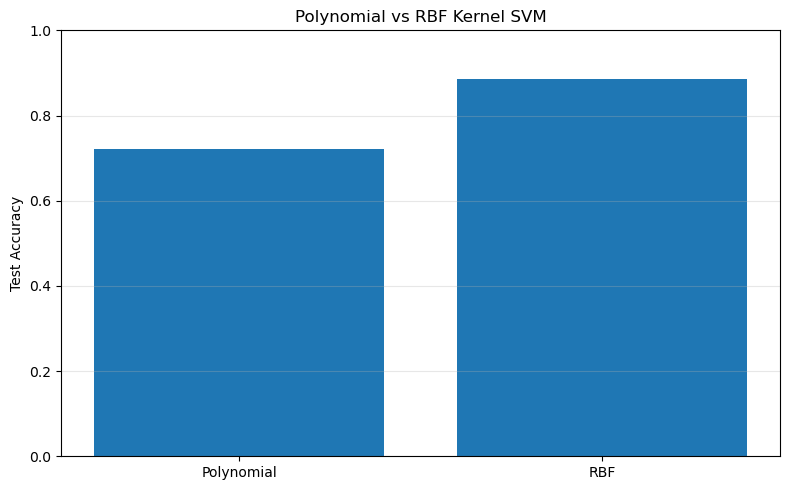

In [33]:
plt.figure(figsize=(8, 5))

plt.bar(
    results_df["Kernel"],
    results_df["Accuracy"]
)

plt.ylabel("Test Accuracy")
plt.title("Polynomial vs RBF Kernel SVM")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()



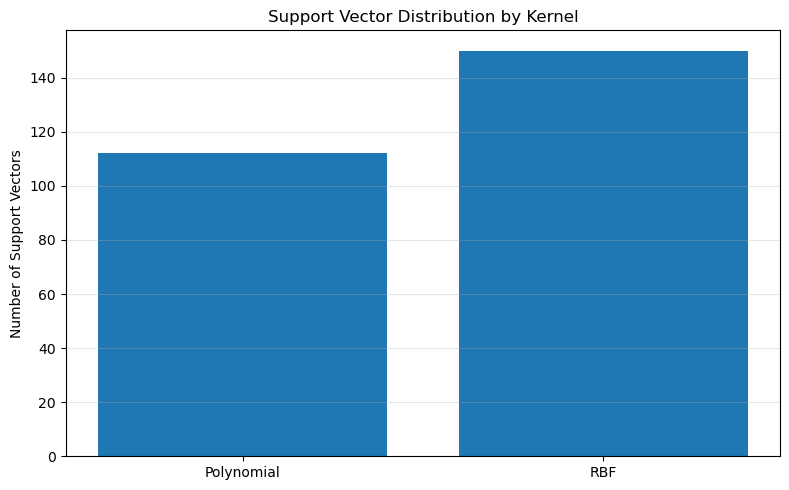

In [34]:
plt.figure(figsize=(8, 5))

plt.bar(
    results_df["Kernel"],
    results_df["Support Vectors"]
)

plt.ylabel("Number of Support Vectors")
plt.title("Support Vector Distribution by Kernel")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()



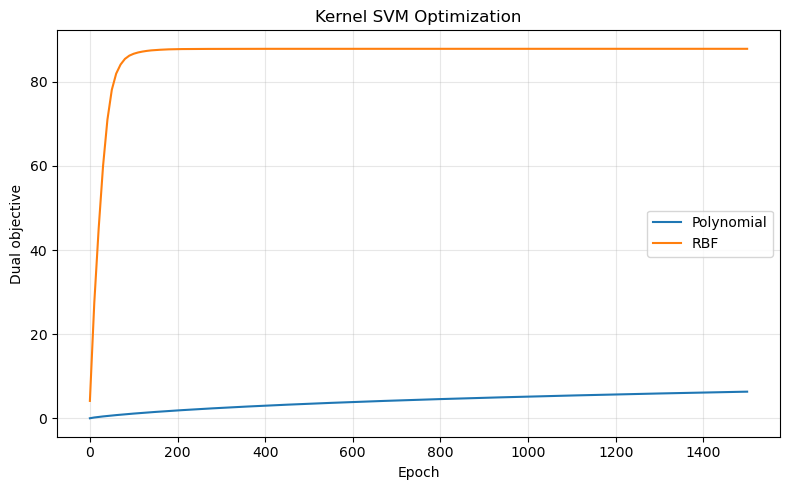

In [35]:
plt.figure(figsize=(8, 5))

for name, model in models.items():
    plt.plot(
        np.arange(len(model.loss_history)) * 10,
        model.loss_history,
        label=name
    )

plt.xlabel("Epoch")
plt.ylabel("Dual objective")
plt.title("Kernel SVM Optimization")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
